In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [3]:
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

In [4]:
# Трансформации с аугментацией для обучения
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),      # Случайное отражение
    transforms.RandomRotation(degrees=10),       # Случайный поворот
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),  # Случайный сдвиг
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))  # Нормализация для RGB
])

# Трансформации для тестовой выборки
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

print("Трансформации для обучения (с аугментацией):")
print("  - RandomHorizontalFlip (p=0.5): случайное отражение")
print("  - RandomRotation (degrees=10): случайный поворот")
print("  - RandomAffine (translate=0.1): случайный сдвиг")
print("  - ToTensor: преобразование в тензор")
print("  - Normalize: нормализация к [-1, 1] (для 3 каналов)")

print("\nТрансформации для теста (без аугментации):")
print("  - ToTensor: преобразование в тензор")
print("  - Normalize: нормализация к [-1, 1] (для 3 каналов)")

Трансформации для обучения (с аугментацией):
  - RandomHorizontalFlip (p=0.5): случайное отражение
  - RandomRotation (degrees=10): случайный поворот
  - RandomAffine (translate=0.1): случайный сдвиг
  - ToTensor: преобразование в тензор
  - Normalize: нормализация к [-1, 1] (для 3 каналов)

Трансформации для теста (без аугментации):
  - ToTensor: преобразование в тензор
  - Normalize: нормализация к [-1, 1] (для 3 каналов)


In [5]:
# Загрузка данных CIFAR-10

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']
NUM_CLASSES = 10

trainset = torchvision.datasets.CIFAR10(
    root='./data',
    train=True,
    download=True,
    transform=train_transform
)

testset = torchvision.datasets.CIFAR10(
    root='./data',
    train=False,
    download=True,
    transform=test_transform
)

print(f"Трейн: {len(trainset)} изображений")
print(f"Тест: {len(testset)} изображений")
print(f"Размер одного изображения: {trainset[0][0].shape}")  # torch.Size([3, 32, 32])
print(f"Диапазон значений после нормализации: [{trainset[0][0].min():.2f}, {trainset[0][0].max():.2f}]")

100%|██████████| 170M/170M [00:05<00:00, 32.5MB/s]


Трейн: 50000 изображений
Тест: 10000 изображений
Размер одного изображения: torch.Size([3, 32, 32])
Диапазон значений после нормализации: [-1.00, 1.00]


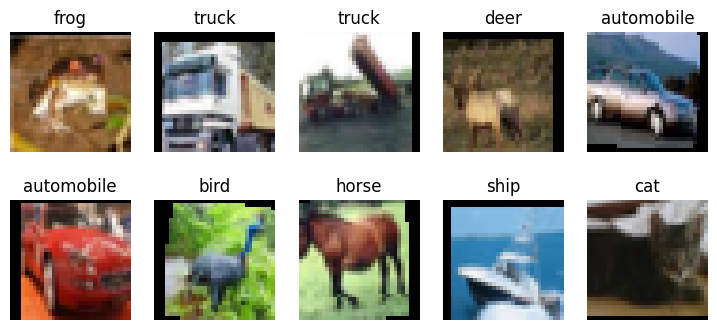

In [6]:
def imshow(images, labels):
    """
    Функция для отображения изображений.
    """
    cols = 5
    rows = 2 if len(images) > 5 else 1
    fig = plt.figure(figsize=(2 * cols - 1, 2.5 * rows - 1))
    for i, (img, label) in enumerate(zip(images, labels)):
        ax = fig.add_subplot(rows, cols, i + 1)
        ax.grid('off')
        ax.axis('off')
        # Денормализуем изображение для отображения
        img_display = img.numpy().transpose((1, 2, 0)) * 0.5 + 0.5
        img_display = np.clip(img_display, 0, 1)
        ax.imshow(img_display)
        ax.set_title(class_names[label])
    plt.show()

# Визуализируем примеры из тренировочной выборки
train_images, train_labels = zip(*[trainset[i] for i in range(10)])
imshow(train_images, train_labels)

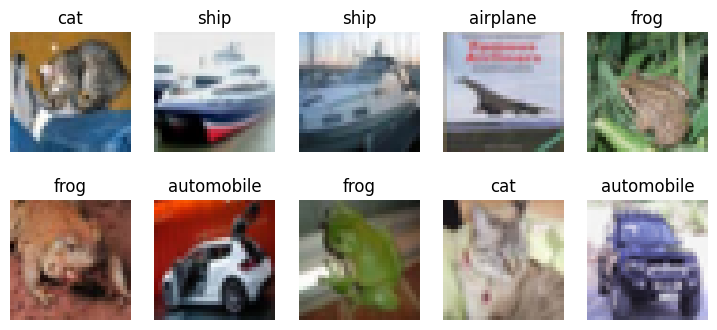

In [7]:
#  Визуализация примеров из тестовой выборки

test_images, test_labels = zip(*[testset[i] for i in range(10)])
imshow(test_images, test_labels)

In [8]:
# Определяем устройство для вычислений (GPU если доступен)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [9]:
#  DataLoader

BATCH_SIZE = 64

trainloader = DataLoader(trainset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
testloader = DataLoader(testset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Количество батчей в trainloader: {len(trainloader)}")
print(f"Количество батчей в testloader: {len(testloader)}")
print(f"Batch size: {BATCH_SIZE}")

Количество батчей в trainloader: 782
Количество батчей в testloader: 157
Batch size: 64


In [10]:
class AlexNetRGB(nn.Module):

    def __init__(self, num_classes=10):
        super(AlexNetRGB, self).__init__()

        self.features = nn.Sequential(
            # Слой 1: Conv + ReLU + Pooling
            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),  # 32x32 -> 16x16

            # Слой 2: Conv + ReLU + Pooling
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),  # 16x16 -> 8x8

            # Слой 3: Conv + ReLU
            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.ReLU(inplace=True),

            # Слой 4: Conv + ReLU
            nn.Conv2d(128, 128, kernel_size=3, stride=1, padding=1),
            nn.ReLU(inplace=True),

            # Слой 5: Conv + ReLU + Pooling
            nn.Conv2d(128, 64, kernel_size=3, stride=1, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),  # 8x8 -> 4x4
        )

        self.classifier = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(64 * 4 * 4, 256),  # 64 * 16 = 1024
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x

# Создаём модель
model = AlexNetRGB(num_classes=NUM_CLASSES).to(device)


print(model)
print("Структура:")
print("5 свёрточных слоёв:")
print("  - Conv1: 3 - 32 канала, kernel=3×3")
print("  - Conv2: 32 - 64 канала, kernel=3×3")
print("  - Conv3: 64 - 128 канала, kernel=3×3")
print("  - Conv4: 128 - 128 канала, kernel=3×3")
print("  - Conv5: 128 - 64 канала, kernel=3×3")
print("пулинг (после 1, 2 и 5 слоёв):")
print("  - MaxPool2d после Conv1, Conv2 и Conv5")
print("3 полносвязных (с Dropout 0.5):")
print("  - FC1: 1024 - 256 нейронов + Dropout")
print("  - FC2: 256 - 128 нейронов + Dropout")
print("  - FC3: 128 - 10 нейронов (выходной)")
print(f"всего параметров: {sum(p.numel() for p in model.parameters()):,}")


AlexNetRGB(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(128, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Dropout(p=0.5, inplace=False)
    (1): Linear(in_features=1024, out_features=256, bias=True)
    (2): ReLU(inplace=True)
    (3): Dropout(p=0.5, inp

In [11]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print(f"Оптимизатор: Adam, learning rate: 0.001")
print(f"Функция потерь: CrossEntropyLoss")

Оптимизатор: Adam, learning rate: 0.001
Функция потерь: CrossEntropyLoss


In [12]:
#  Функция для обучения модели

def train_model(model, trainloader, testloader, criterion, optimizer, epochs=15):
    """
    Функция для обучения модели.
    Возвращает историю обучения (loss и accuracy).
    """
    history = {
        'train_loss': [],
        'train_acc': [],
        'val_loss': [],
        'val_acc': []
    }

    for epoch in range(epochs):
        # Фаза обучения
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for i, (inputs, labels) in enumerate(trainloader):
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

            if (i + 1) % 100 == 0:
                print(f'Epoch [{epoch+1}/{epochs}], Step [{i+1}/{len(trainloader)}], Loss: {loss.item():.4f}')

        train_loss = running_loss / len(trainloader)
        train_acc = 100. * correct / total

        # Фаза валидации
        model.eval()
        val_loss = 0.0
        correct_val = 0
        total_val = 0

        with torch.no_grad():
            for inputs, labels in testloader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_loss += loss.item()
                _, predicted = outputs.max(1)
                total_val += labels.size(0)
                correct_val += predicted.eq(labels).sum().item()

        val_loss = val_loss / len(testloader)
        val_acc = 100. * correct_val / total_val

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        print(f'Epoch [{epoch+1}/{epochs}] Summary:')
        print(f'Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%')
        print(f'Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%')
        print('-' * 60)

    return history

In [14]:
EPOCHS = 20
print(f"Количество эпох: {EPOCHS}")

history = train_model(model, trainloader, testloader, criterion, optimizer, epochs=EPOCHS)



Количество эпох: 20
Epoch [1/20], Step [100/782], Loss: 1.6350
Epoch [1/20], Step [200/782], Loss: 1.6217
Epoch [1/20], Step [300/782], Loss: 1.2431
Epoch [1/20], Step [400/782], Loss: 1.2623
Epoch [1/20], Step [500/782], Loss: 1.5379
Epoch [1/20], Step [600/782], Loss: 1.3307
Epoch [1/20], Step [700/782], Loss: 1.4723
Epoch [1/20] Summary:
Train Loss: 1.4746, Train Acc: 45.32%
Val Loss: 1.2612, Val Acc: 53.25%
------------------------------------------------------------
Epoch [2/20], Step [100/782], Loss: 1.4215
Epoch [2/20], Step [200/782], Loss: 1.4675
Epoch [2/20], Step [300/782], Loss: 1.3702
Epoch [2/20], Step [400/782], Loss: 1.2324
Epoch [2/20], Step [500/782], Loss: 1.2332
Epoch [2/20], Step [600/782], Loss: 1.2129
Epoch [2/20], Step [700/782], Loss: 1.2539
Epoch [2/20] Summary:
Train Loss: 1.2960, Train Acc: 53.08%
Val Loss: 1.0877, Val Acc: 60.11%
------------------------------------------------------------
Epoch [3/20], Step [100/782], Loss: 1.2138
Epoch [3/20], Step [200/7

In [20]:
# проверка на переобучение
train_acc = history['train_acc'][-1]
val_acc = history['val_acc'][-1]

print(f"Точность на обучении: {train_acc:.2f}%")
print(f"Точность на валидации: {val_acc:.2f}%")

if train_acc - val_acc > 10:
    print("Есть переобучение")
else:
    print("Переобучения нет")

Точность на обучении: 76.83%
Точность на валидации: 78.97%
Переобучения нет


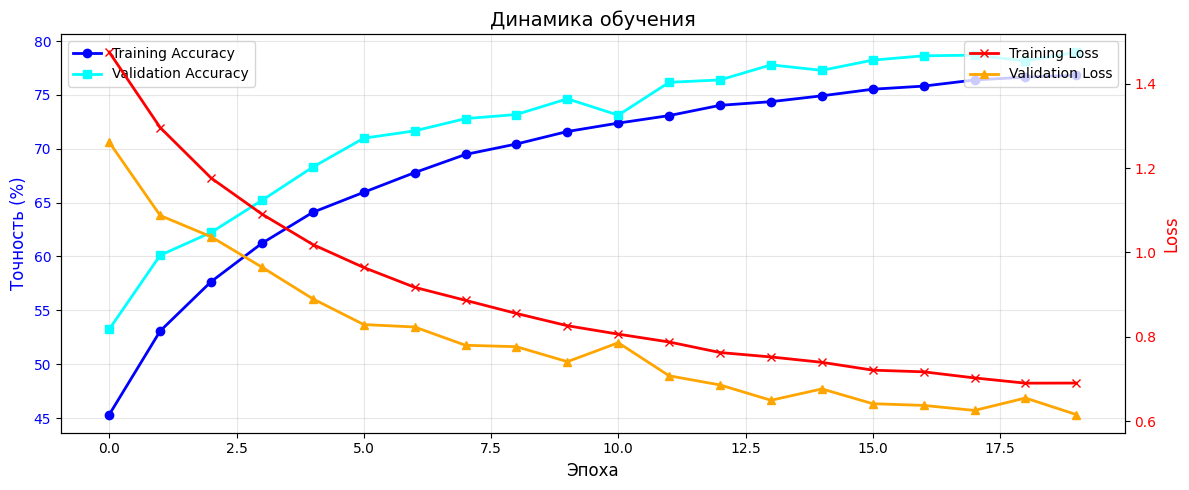

In [21]:
# График обучения
fig, ax1 = plt.subplots(figsize=(12, 5))

# График точности
ax1.set_xlabel('Эпоха', fontsize=12)
ax1.set_ylabel('Точность (%)', color='blue', fontsize=12)
ax1.plot(history['train_acc'], marker='o', label='Training Accuracy', color='blue', linewidth=2)
ax1.plot(history['val_acc'], marker='s', label='Validation Accuracy', color='cyan', linewidth=2)
ax1.tick_params(axis='y', labelcolor='blue')
ax1.legend(loc='upper left')
ax1.grid(True, alpha=0.3)

# График потерь
ax2 = ax1.twinx()
ax2.set_ylabel('Loss', color='red', fontsize=12)
ax2.plot(history['train_loss'], marker='x', label='Training Loss', color='red', linewidth=2)
ax2.plot(history['val_loss'], marker='^', label='Validation Loss', color='orange', linewidth=2)
ax2.tick_params(axis='y', labelcolor='red')
ax2.legend(loc='upper right')

plt.title('Динамика обучения', fontsize=14)
plt.tight_layout()
plt.show()


Training Accuracy - растёт на протяжении всех эпох

Validation Accuracy - также растет, но с небольшими колебаниями, отставая от тренировочной точности.

Training Loss - снижается, что говорит о хорошем усвоении данных.

Validation Loss - снижается

In [22]:
model.eval()
y_pred = []
y_true = []

with torch.no_grad():
    for inputs, labels in testloader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        _, predicted = torch.max(outputs, 1)
        y_pred.extend(predicted.cpu().numpy())
        y_true.extend(labels.numpy())

y_pred = np.array(y_pred)
y_true = np.array(y_true)

print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

accuracy = np.mean(y_pred == y_true) * 100
print(f"Общая точность модели: {accuracy:.2f}%")
print(f"Количество ошибок: {np.sum(y_pred != y_true)} из {len(y_true)}")

Classification Report:
              precision    recall  f1-score   support

    airplane       0.82      0.81      0.82      1000
  automobile       0.90      0.92      0.91      1000
        bird       0.71      0.66      0.69      1000
         cat       0.64      0.51      0.57      1000
        deer       0.76      0.76      0.76      1000
         dog       0.64      0.77      0.70      1000
        frog       0.84      0.86      0.85      1000
       horse       0.80      0.84      0.82      1000
        ship       0.88      0.90      0.89      1000
       truck       0.91      0.86      0.88      1000

    accuracy                           0.79     10000
   macro avg       0.79      0.79      0.79     10000
weighted avg       0.79      0.79      0.79     10000

Общая точность модели: 78.97%
Количество ошибок: 2103 из 10000


Всего ошибок: 2103 из 10000


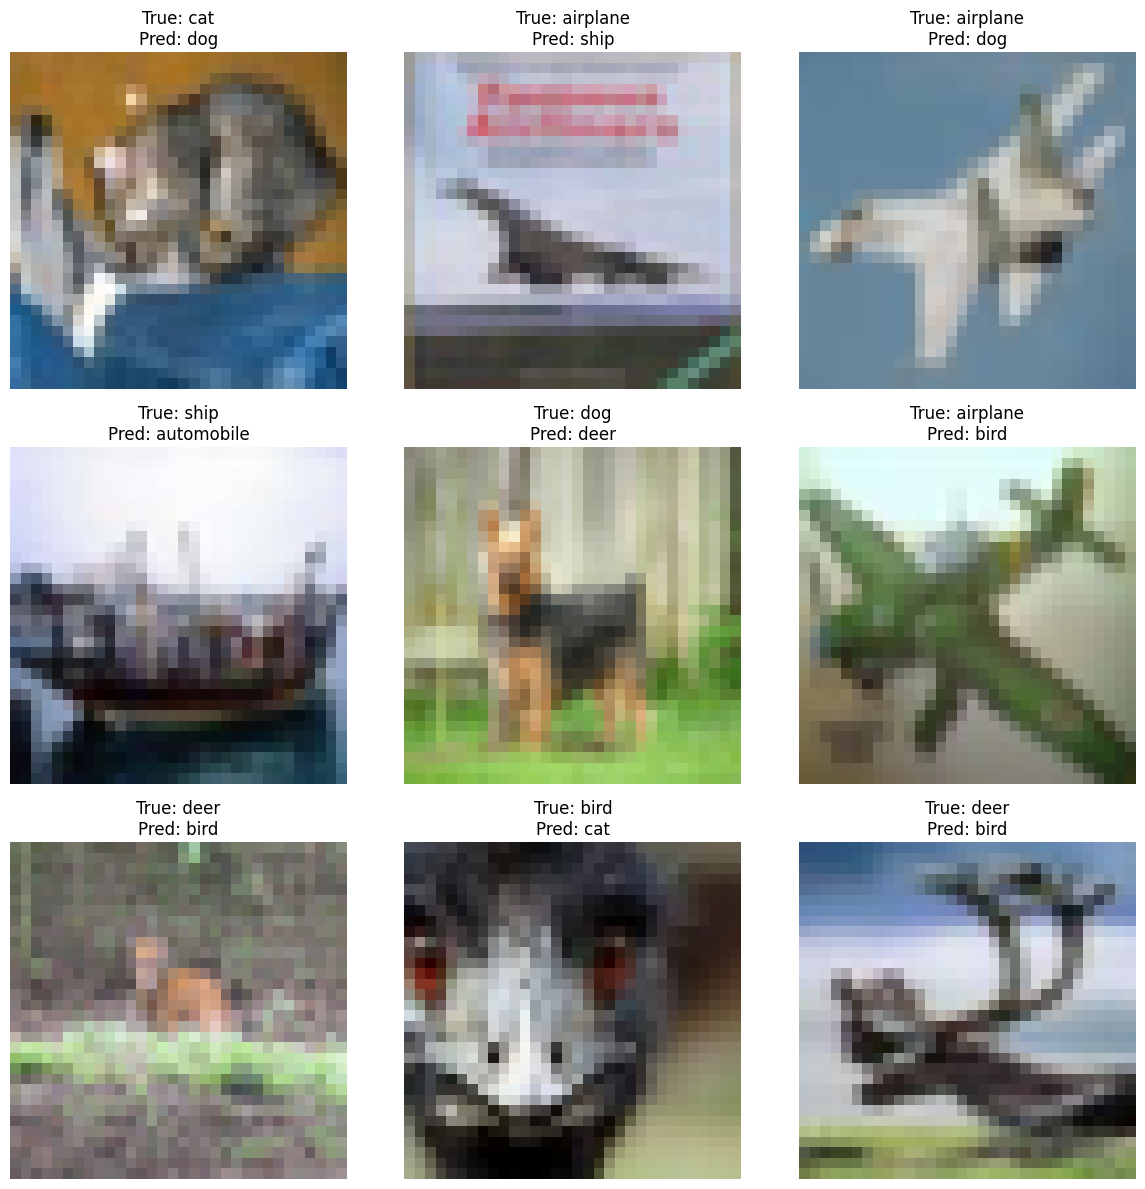

In [18]:
# Визуализация ошибок

errors = np.where(y_pred != y_true)[0]
print(f"Всего ошибок: {len(errors)} из {len(y_true)}")

plt.figure(figsize=(12, 12))
for i in range(min(9, len(errors))):
    idx = errors[i]
    plt.subplot(3, 3, i+1)

    # Денормализуем изображение для отображения
    img = testset[idx][0].numpy().transpose((1, 2, 0)) * 0.5 + 0.5
    img = np.clip(img, 0, 1)
    plt.imshow(img)
    plt.title(f'True: {class_names[y_true[idx]]}\nPred: {class_names[y_pred[idx]]}')
    plt.axis('off')

plt.tight_layout()
plt.show()

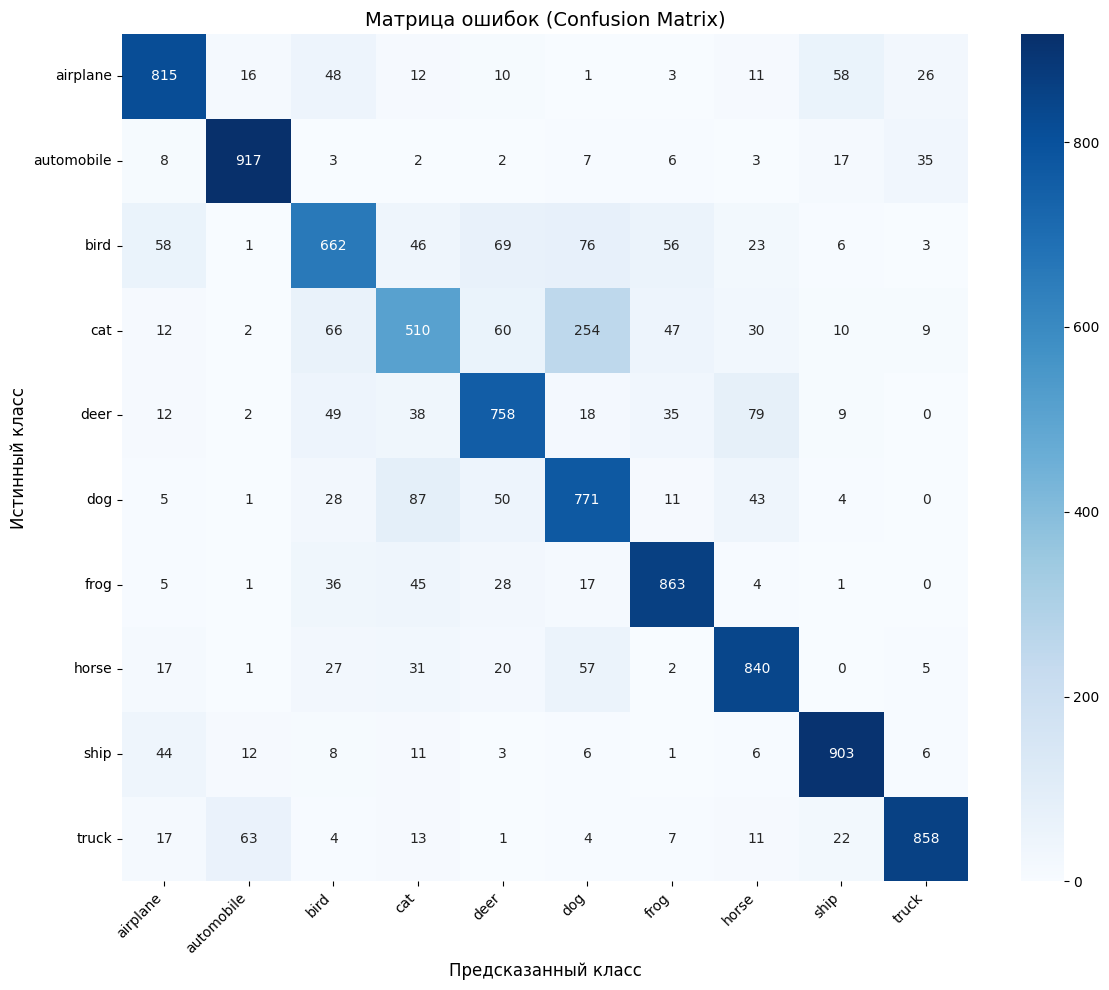

In [23]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.xlabel('Предсказанный класс', fontsize=12)
plt.ylabel('Истинный класс', fontsize=12)
plt.title('Матрица ошибок (Confusion Matrix)', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Модель AlexNet  достигла точности 78.97%. Основные ошибки возникают при предсказании классов кошки/собаки, птицы/олени.Лучшие классы :automobile, truck, frog , ship, airplane, horse. 